# OLSを最尤推定から導出する

## 概要

通常最小二乗法（OLS）は残差平方和を最小にする方法である。独立で等分散の正規誤差を仮定し、尤度からOLSを導く。係数と誤差分散の推定をPythonとグラフで確かめる。

## 実行環境

仮想環境・カーネル名は `wa-src(3.14.6)`、Pythonは `3.14.6` である。上から順に実行する。小数は有効数字3桁で表示し、計算では丸めない。図は `101_nb_files` にSVGで保存し、出力欄にも埋め込む。

In [1]:
import base64
import platform
import sys
from io import BytesIO
from pathlib import Path
from pprint import pprint

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
from IPython.display import Latex, display
from matplotlib.ticker import FuncFormatter
from scipy.optimize import minimize
from scipy.stats import norm

assert sys.version_info[:3] == (3, 14, 6)
print(f"Python: {platform.python_version()}")
print(f"実行ファイル: {sys.executable}")
print(f"OS: {platform.system()} {platform.release()}")
print(f"NumPy: {np.__version__}, SciPy: {scipy.__version__}")
print(f"Matplotlib: {matplotlib.__version__}")


def sig3(value):
    # 末尾のゼロも残して、有効数字3桁にそろえる。
    return format(float(value), "#.3g")


np.set_printoptions(formatter={"float_kind": sig3})
plt.rcParams.update({"font.size": 11, "axes.grid": True,
                     "grid.alpha": 0.250, "svg.hashsalt": "ols-101"})
image_dir = Path("101_nb_files")
image_dir.mkdir(exist_ok=True)


def save_svg(fig, filename):
    # 各軸とカラーバーの目盛りにも同じ表示規則を適用する。
    for ax in fig.axes:
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: sig3(x)))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: sig3(y)))
    path = image_dir / filename
    fig.savefig(path, format="svg", bbox_inches="tight", metadata={"Date": None})
    # SVGを許可しないビューアー用に、表示用PNGもメモリ上で作る。
    png_buffer = BytesIO()
    fig.savefig(png_buffer, format="png", dpi=150, bbox_inches="tight")
    plt.close(fig)
    display({"image/svg+xml": path.read_text(encoding="utf-8"),
             "image/png": base64.b64encode(png_buffer.getvalue()).decode("ascii")},
            raw=True)

Python: 3.14.6
実行ファイル: /Users/hiroshi/private/wa_src/.venv/bin/python
OS: Darwin 25.5.0
NumPy: 2.5.4, SciPy: 1.18.1
Matplotlib: 3.11.2


## 1. 線形モデルと誤差の仮定

観測数を $n$、切片を含む係数の数を $p$ とする。説明変数を固定し、行列とベクトルで次のように書く。

$$
\mathbf{y}=\mathbf{X}\mathbf{b}+\mathbf{u},\qquad
\mathbf{y},\mathbf{u}\in\mathbb{R}^{n},\quad
\mathbf{X}\in\mathbb{R}^{n\times p},\quad
\mathbf{b}\in\mathbb{R}^{p}.
$$

$\mathbf{X}$ の第 $i$ 行を $\mathbf{x}_i^{\mathsf T}$ とすると、$y_i=\mathbf{x}_i^{\mathsf T}\mathbf{b}+u_i$ である。条件付きで $u_i$ は互いに独立、$u_i\sim N(0,v)$、$v=\sigma^2>0$ と仮定する。したがって、観測値の条件付き密度は

$$
f(y_i\mid\mathbf{x}_i,\mathbf{b},v)
=\frac{1}{\sqrt{2\pi v}}
\exp\left[-\frac{(y_i-\mathbf{x}_i^{\mathsf T}\mathbf{b})^2}{2v}\right]
$$

となる。以下では $n>p$、$\operatorname{rank}(\mathbf{X})=p$ とする。正規性はこの最尤推定との対応に使う仮定であり、OLSの計算自体には不要である。

## 2. 尤度を対数に変換する

独立性により同時密度は積になる。観測値を固定し、未知の $\mathbf{b},v$ の関数として見るものが尤度である。

$$
\begin{aligned}
L(\mathbf{b},v)
&=\prod_{i=1}^{n}\frac{1}{\sqrt{2\pi v}}
\exp\left[-\frac{(y_i-\mathbf{x}_i^{\mathsf T}\mathbf{b})^2}{2v}\right]\\
&=(2\pi v)^{-n/2}\exp\left[-\frac{1}{2v}
\sum_{i=1}^{n}(y_i-\mathbf{x}_i^{\mathsf T}\mathbf{b})^2\right],\\
S(\mathbf{b})&=\sum_{i=1}^{n}(y_i-\mathbf{x}_i^{\mathsf T}\mathbf{b})^2,\\
\ell(\mathbf{b},v)=\log L(\mathbf{b},v)
&=-\frac n2\log(2\pi)-\frac n2\log v-\frac{S(\mathbf{b})}{2v}.
\end{aligned}
$$

対数は単調増加なので最大点を変えない。固定した $v>0$ では、前の2項は係数に依存せず、最後の項の係数は負である。したがって対数尤度の最大化は $S$ の最小化と同じである。私はこの符号を確認すると理解しやすいと感じる。

## 3. 微分してOLSを得る

残差平方和を展開する。中央の2項は互いに転置されたスカラーなので等しい。

$$
\begin{aligned}
S(\mathbf{b})
&=(\mathbf{y}-\mathbf{X}\mathbf{b})^{\mathsf T}
(\mathbf{y}-\mathbf{X}\mathbf{b})\\
&=\mathbf{y}^{\mathsf T}\mathbf{y}
-\mathbf{y}^{\mathsf T}\mathbf{X}\mathbf{b}
-\mathbf{b}^{\mathsf T}\mathbf{X}^{\mathsf T}\mathbf{y}
+\mathbf{b}^{\mathsf T}\mathbf{X}^{\mathsf T}\mathbf{X}\mathbf{b}\\
&=\mathbf{y}^{\mathsf T}\mathbf{y}
-2\mathbf{b}^{\mathsf T}\mathbf{X}^{\mathsf T}\mathbf{y}
+\mathbf{b}^{\mathsf T}\mathbf{X}^{\mathsf T}\mathbf{X}\mathbf{b}.
\end{aligned}
$$

成分 $b_j$ による微分を並べれば、勾配になる。

$$
\begin{aligned}
\frac{\partial S}{\partial b_j}
&=\sum_i2\left(y_i-\sum_kx_{ik}b_k\right)(-x_{ij}),\\
\nabla_{\mathbf{b}}S
&=-2\mathbf{X}^{\mathsf T}(\mathbf{y}-\mathbf{X}\mathbf{b}),\\
\nabla_{\mathbf{b}}\ell
&=-\frac{1}{2v}\nabla_{\mathbf{b}}S
=\frac{1}{v}\mathbf{X}^{\mathsf T}(\mathbf{y}-\mathbf{X}\mathbf{b}).
\end{aligned}
$$

勾配をゼロと置くと、正規方程式が得られる。

<div>

$$
\mathbf{X}^{\mathsf T}\mathbf{y}
-\mathbf{X}^{\mathsf T}\mathbf{X}\hat{\mathbf{b}}=\mathbf{0}
\quad\Longrightarrow\quad
\boxed{\hat{\mathbf{b}}=(\mathbf{X}^{\mathsf T}\mathbf{X})^{-1}
\mathbf{X}^{\mathsf T}\mathbf{y}}.
$$

</div>

対数尤度のヘッセ行列は $-\mathbf{X}^{\mathsf T}\mathbf{X}/v$ である。任意の非ゼロベクトル $\mathbf{a}$ について、$-\mathbf{a}^{\mathsf T}\mathbf{X}^{\mathsf T}\mathbf{X}\mathbf{a}/v=-\|\mathbf{X}\mathbf{a}\|^2/v<0$ なので、固定した $v$ で最大点は一意である。列が独立でなければ係数は一意にならず、上の逆行列も存在しない。

## 4. 未知の分散も推定する

$S_*=S(\hat{\mathbf{b}})>0$ とする。係数をその推定値に固定し、分散で微分する。

$$
\begin{aligned}
\frac{\partial\ell}{\partial v}
&=-\frac{n}{2v}+\frac{S_*}{2v^2}
=\frac{S_*-nv}{2v^2},\\
\frac{\partial\ell}{\partial v}=0
&\Longleftrightarrow S_*-nv=0
\Longleftrightarrow\hat v_{\mathrm{ML}}=\frac{S_*}{n}.
\end{aligned}
$$

$v<S_*/n$ では微分が正、$v>S_*/n$ では負である。係数の最大点はどの $v$ でも同じなので、この組が同時最尤推定になる。$S_*=0$ では $v\to0$ で尤度が発散し、正の分散で有限の最大点を持たない。

分散の最尤推定は不偏ではない。同じモデルで $E[S_*]=(n-p)v$ なので、

$$
E[\hat v_{\mathrm{ML}}]=\frac{n-p}{n}v,
\qquad s^2=\frac{S_*}{n-p},\qquad E[s^2]=v.
$$

係数を推定した分だけ残差の自由度が減る。分母が $n$ か $n-p$ かは、推定方法の違いである。

In [2]:
# 重要な結果はLaTeX形式でも出力する。
display(Latex(
    r"\(\boxed{\hat{\mathbf{b}}_{\mathrm{ML}}=\hat{\mathbf{b}}_{\mathrm{OLS}}"
    r"=(\mathbf{X}^{\mathsf T}\mathbf{X})^{-1}\mathbf{X}^{\mathsf T}\mathbf{y}},"
    r"\quad\boxed{\hat\sigma^2_{\mathrm{ML}}=S_*/n}\)"
))

<IPython.core.display.Latex object>

## 5. 小さなデータで計算する

4点 $(x_i,y_i)=(0,1),(1,2),(2,2),(3,4)$ に $y_i\approx b_0+b_1x_i$ を当てはめる。

$$
\mathbf{X}=\begin{bmatrix}1&0\\1&1\\1&2\\1&3\end{bmatrix},\quad
\mathbf{y}=\begin{bmatrix}1\\2\\2\\4\end{bmatrix},\quad
\mathbf{X}^{\mathsf T}\mathbf{X}=\begin{bmatrix}4&6\\6&14\end{bmatrix},\quad
\mathbf{X}^{\mathsf T}\mathbf{y}=\begin{bmatrix}9\\18\end{bmatrix}.
$$

正規方程式は $4b_0+6b_1=9$、$6b_0+14b_1=18$。第1式の3倍を第2式の2倍から引くと、$10b_1=9$。よって $b_1=0.900$、$b_0=(9-6\times0.900)/4=0.900$ となる。

$$
\mathbf{r}=\begin{bmatrix}0.100\\0.200\\-0.700\\0.400\end{bmatrix},\quad
S_*=0.100^2+0.200^2+(-0.700)^2+0.400^2=0.700.
$$

したがって $\hat v_{\mathrm{ML}}=0.700/4=0.175$、$s^2=0.700/2=0.350$ である。実装では逆行列を明示的に作らず、`lstsq` で最小二乗問題を解く。

In [3]:
x_small = np.arange(4)
X_small = np.column_stack([np.ones(4), x_small])
y_small = np.array([1, 2, 2, 4])
b_small = np.linalg.lstsq(X_small, y_small, rcond=None)[0]
r_small = y_small - X_small @ b_small
rss_small = r_small @ r_small

pprint({"係数 [切片, 傾き]": b_small, "残差": r_small,
        "RSS": sig3(rss_small), "分散MLE": sig3(rss_small / 4),
        "不偏分散": sig3(rss_small / 2)})
display(Latex(
    rf"\(\hat{{\mathbf{{b}}}}=\begin{{bmatrix}}{sig3(b_small[0])}"
    rf"\\{sig3(b_small[1])}\end{{bmatrix}},\quad"
    rf"\hat v_{{\mathrm{{ML}}}}={sig3(rss_small / 4)}\)"
))
np.testing.assert_allclose(b_small, [0.900, 0.900])
np.testing.assert_allclose(rss_small, 0.700)

{'RSS': '0.700',
 '不偏分散': '0.350',
 '係数 [切片, 傾き]': array([0.900, 0.900]),
 '分散MLE': '0.175',
 '残差': array([0.100, 0.200, -0.700, 0.400])}


<IPython.core.display.Latex object>

## 6. Pythonで最尤推定と比較する

80点の人工データを作る。真の切片は $1.50$、傾きは $0.800$、誤差の標準偏差は $0.600$ とする。数値最適化では $v=\exp(\eta)$ と置いて分散を正に保ち、係数と $\eta$ を同時に推定する。

In [4]:
rng = np.random.default_rng(101)
n = 80
x = np.linspace(-2, 2, n)
X = np.column_stack([np.ones(n), x])
p = X.shape[1]
b_true = np.array([1.50, 0.800])
sigma_true = 0.600
y = X @ b_true + rng.normal(0, sigma_true, n)

b_ols = np.linalg.lstsq(X, y, rcond=None)[0]
residual = y - X @ b_ols
rss = residual @ residual
v_mle = rss / n
v_unbiased = rss / (n - p)


def negative_log_likelihood(theta):
    # 最後の成分は分散の対数。定数項も含めて計算する。
    b, eta = theta[:-1], theta[-1]
    v = np.exp(eta)
    r = y - X @ b
    return n / 2 * (np.log(2 * np.pi) + eta) + (r @ r) / (2 * v)


def nll_gradient(theta):
    b, eta = theta[:-1], theta[-1]
    v = np.exp(eta)
    r = y - X @ b
    # d(-ell)/d eta = n/2 - S/(2v) も解析的に与える。
    return np.r_[-X.T @ r / v, n / 2 - (r @ r) / (2 * v)]


result = minimize(negative_log_likelihood, np.zeros(p + 1),
                  jac=nll_gradient, method="BFGS", options={"gtol": 1.00e-7})
b_mle = result.x[:-1]
v_numeric = np.exp(result.x[-1])
pprint({"OLS": b_ols, "数値MLE": b_mle,
        "分散MLE（解析）": sig3(v_mle), "分散MLE（数値）": sig3(v_numeric),
        "不偏分散": sig3(v_unbiased), "最適化成功": bool(result.success)})

# 最適化結果を閉形式の解と照合し、密度の和からも尤度を確認する。
assert result.success, result.message
np.testing.assert_allclose(b_mle, b_ols, rtol=1.00e-7, atol=1.00e-8)
np.testing.assert_allclose(v_numeric, v_mle, rtol=1.00e-7)
np.testing.assert_allclose(X.T @ residual, np.zeros(p), atol=1.00e-12)
theta_ols = np.r_[b_ols, np.log(v_mle)]
np.testing.assert_allclose(
    negative_log_likelihood(theta_ols),
    -norm.logpdf(y, loc=X @ b_ols, scale=np.sqrt(v_mle)).sum(),
)
display(Latex(
    rf"\(\hat y={sig3(b_ols[0])}+{sig3(b_ols[1])}x,\quad"
    rf"\hat\sigma^2_{{\mathrm{{ML}}}}={sig3(v_mle)}\)"
))

{'OLS': array([1.50, 0.763]),
 '不偏分散': '0.420',
 '分散MLE（数値）': '0.409',
 '分散MLE（解析）': '0.409',
 '数値MLE': array([1.50, 0.763]),
 '最適化成功': True}


<IPython.core.display.Latex object>

### 回帰直線と残差

左は観測値と推定直線、右は残差である。OLSと最尤推定の直線は重なる。残差図だけで正規性や独立性を証明することはできない。

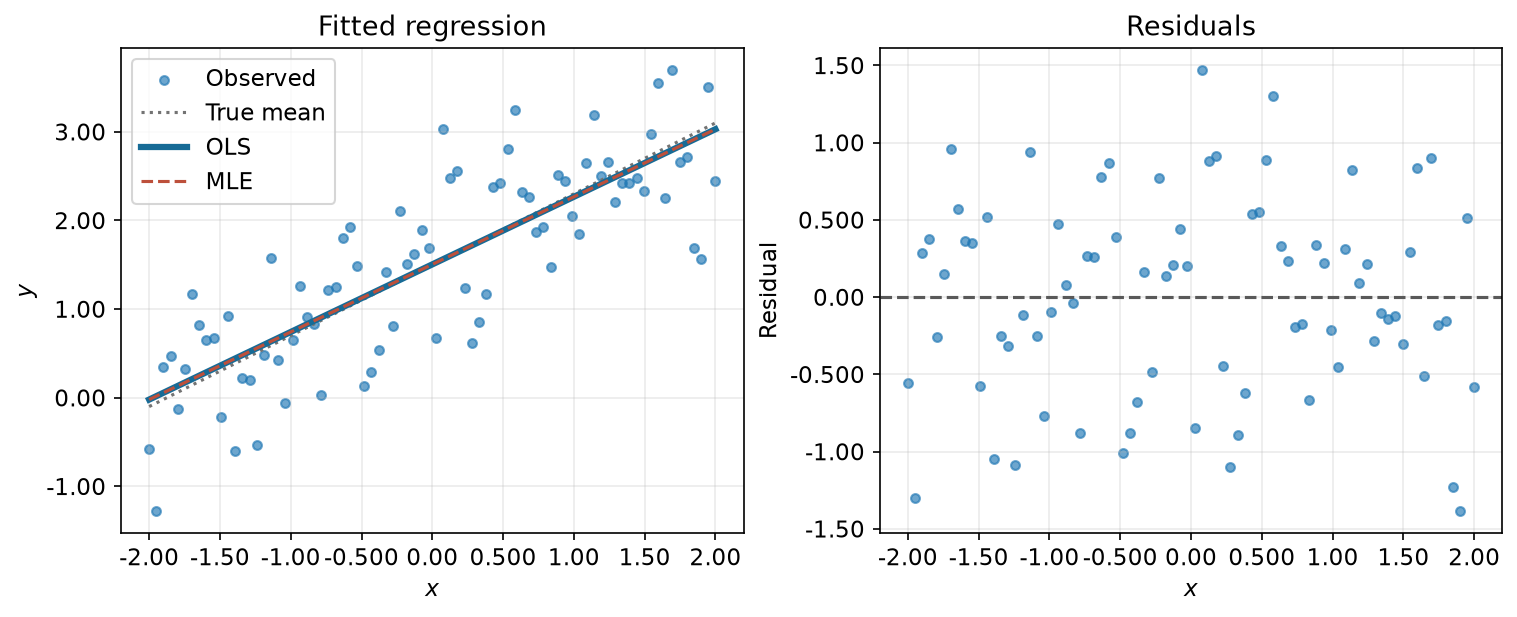

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
axes[0].scatter(x, y, s=18, alpha=0.650, label="Observed")
axes[0].plot(x, X @ b_true, color="0.450", linestyle=":", label="True mean")
axes[0].plot(x, X @ b_ols, color="#176b96", linewidth=3, label="OLS")
axes[0].plot(x, X @ b_mle, color="#bd503b", linestyle="--", label="MLE")
axes[0].set(xlabel="$x$", ylabel="$y$", title="Fitted regression")
axes[0].legend()
axes[1].scatter(x, residual, s=18, alpha=0.650)
axes[1].axhline(0, color="0.350", linestyle="--")
axes[1].set(xlabel="$x$", ylabel="Residual", title="Residuals")
save_svg(fig, "ols_01_fit_residuals.svg")

### 残差平方和と対数尤度

分散を推定値に固定すると、左の最小点と右の最大点が一致する。続く図は切片も固定し、傾きだけを変えた断面である。

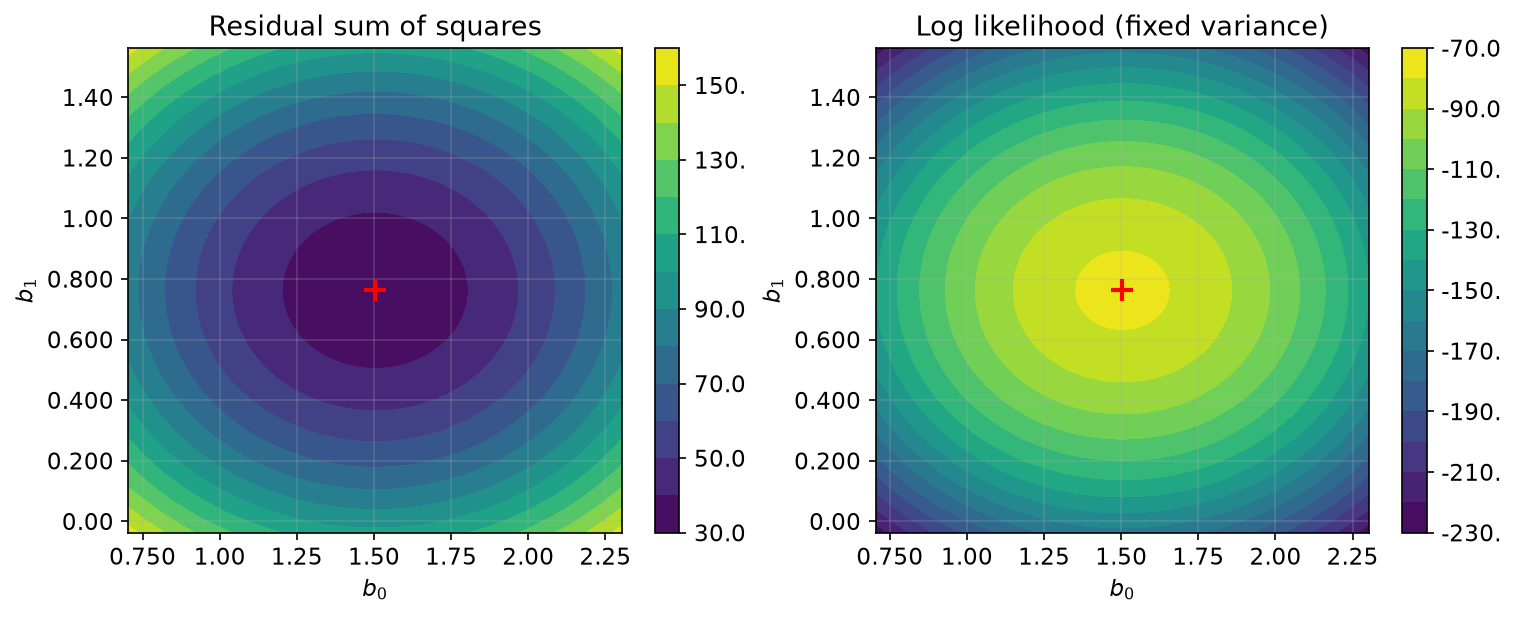

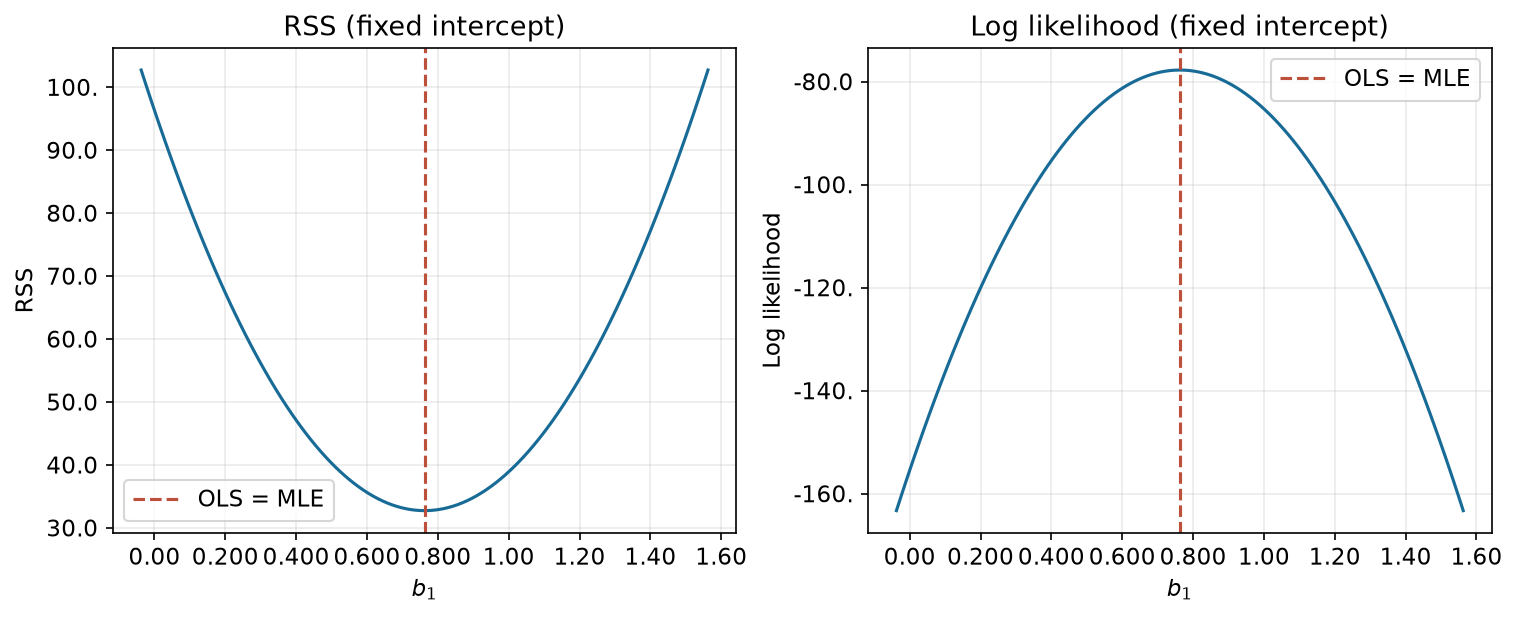

In [6]:
b0_grid = np.linspace(b_ols[0] - 0.800, b_ols[0] + 0.800, 121)
b1_grid = np.linspace(b_ols[1] - 0.800, b_ols[1] + 0.800, 121)
B0, B1 = np.meshgrid(b0_grid, b1_grid)
# 最後の軸を観測に対応させ、候補ごとの残差平方和を計算する。
grid_residual = y - B0[..., None] - B1[..., None] * x
S_grid = np.sum(grid_residual**2, axis=-1)
ell_grid = -n / 2 * np.log(2 * np.pi * v_mle) - S_grid / (2 * v_mle)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, values, title in zip(axes, [S_grid, ell_grid],
                             ["Residual sum of squares", "Log likelihood (fixed variance)"]):
    contour = ax.contourf(B0, B1, values, levels=14, cmap="viridis")
    ax.plot(*b_ols, "r+", markersize=11, markeredgewidth=2)
    ax.set(xlabel="$b_0$", ylabel="$b_1$", title=title)
    fig.colorbar(contour, ax=ax)
save_svg(fig, "ols_02_contours.svg")

S_slice = np.sum((y - b_ols[0] - b1_grid[:, None] * x)**2, axis=1)
ell_slice = -n / 2 * np.log(2 * np.pi * v_mle) - S_slice / (2 * v_mle)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, values, label in zip(axes, [S_slice, ell_slice], ["RSS", "Log likelihood"]):
    ax.plot(b1_grid, values, color="#176b96")
    ax.axvline(b_ols[1], color="#bd503b", linestyle="--", label="OLS = MLE")
    ax.set(xlabel="$b_1$", ylabel=label, title=label + " (fixed intercept)")
    ax.legend()
save_svg(fig, "ols_03_slope_slice.svg")

### 分散の推定

係数をOLS解に固定した対数尤度は $S_*/n$ で最大になる。不偏分散 $S_*/(n-p)$ は、その最大点とは異なる。

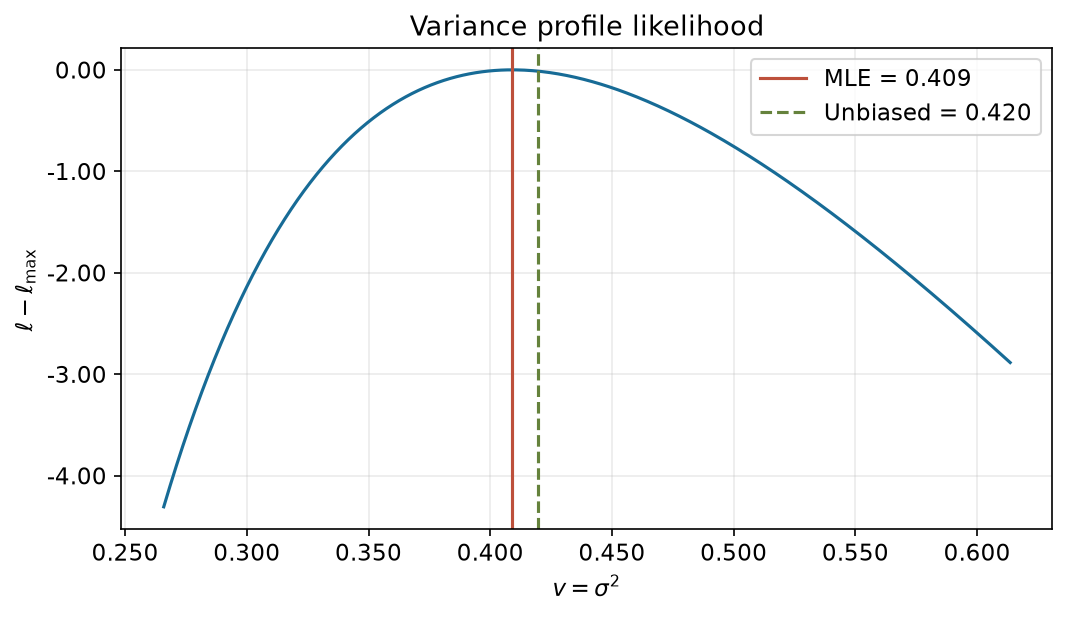

In [7]:
v_grid = np.linspace(v_mle * 0.650, v_mle * 1.50, 400)
ell_v = -n / 2 * np.log(2 * np.pi * v_grid) - rss / (2 * v_grid)
ell_max = -negative_log_likelihood(theta_ols)
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.plot(v_grid, ell_v - ell_max, color="#176b96")
ax.axvline(v_mle, color="#bd503b", label=f"MLE = {sig3(v_mle)}")
ax.axvline(v_unbiased, color="#65823c", linestyle="--",
           label=f"Unbiased = {sig3(v_unbiased)}")
ax.set(xlabel=r"$v=\sigma^2$", ylabel=r"$\ell-\ell_{\max}$",
       title="Variance profile likelihood")
ax.legend()
save_svg(fig, "ols_04_variance_profile.svg")

20点の回帰を5000回繰り返し、分散推定値の平均も比較する。真の分散は $0.360$、最尤推定値の期待値は $(18/20)\times0.360=0.324$ である。分布は重なるが、最尤推定値の平均は小さくなる。

{'MLEの標本平均': '0.321',
 'MLEの理論平均': '0.324',
 '不偏推定の標本平均': '0.357',
 '真の分散': '0.360'}


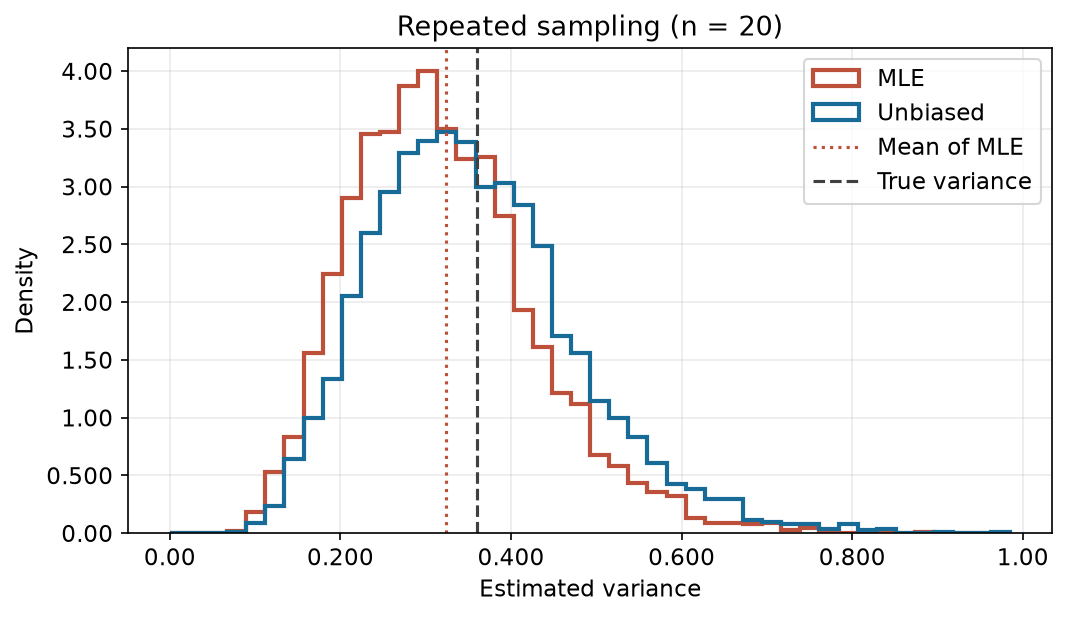

In [8]:
sim_rng = np.random.default_rng(102)
n_sim, repeats = 20, 5000
X_sim = np.column_stack([np.ones(n_sim), np.linspace(-2, 2, n_sim)])
# 各列を1回分の観測データとして、まとめて最小二乗問題を解く。
Y_sim = (X_sim @ b_true)[:, None] + sim_rng.normal(
    0, sigma_true, size=(n_sim, repeats)
)
B_sim = np.linalg.lstsq(X_sim, Y_sim, rcond=None)[0]
R_sim = Y_sim - X_sim @ B_sim
rss_sim = np.sum(R_sim**2, axis=0)
mle_sim = rss_sim / n_sim
unbiased_sim = rss_sim / (n_sim - p)
v_true = sigma_true**2
expected_mle = (n_sim - p) / n_sim * v_true
pprint({"真の分散": sig3(v_true), "MLEの理論平均": sig3(expected_mle),
        "MLEの標本平均": sig3(mle_sim.mean()),
        "不偏推定の標本平均": sig3(unbiased_sim.mean())})

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
bins = np.linspace(0, max(mle_sim.max(), unbiased_sim.max()), 45)
ax.hist(mle_sim, bins=bins, density=True, histtype="step", linewidth=2,
        color="#bd503b", label="MLE")
ax.hist(unbiased_sim, bins=bins, density=True, histtype="step", linewidth=2,
        color="#176b96", label="Unbiased")
ax.axvline(expected_mle, color="#bd503b", linestyle=":", label="Mean of MLE")
ax.axvline(v_true, color="0.250", linestyle="--", label="True variance")
ax.set(xlabel="Estimated variance", ylabel="Density", title="Repeated sampling (n = 20)")
ax.legend()
save_svg(fig, "ols_05_variance_sampling.svg")

## 結論

この記事では、独立で等分散の正規誤差を仮定し、最尤推定からOLSと誤差分散の推定式を導いた。

対数尤度の係数に依存する部分は、残差平方和の負の定数倍である。このため係数の最尤推定値はOLS解と一致する。分散の最尤推定は残差平方和を $n$ で割り、不偏推定は $n-p$ で割る。誤差に相関や不等分散がある場合、この尤度はそのまま使えず、通常のOLSと最尤推定が一致するとは限らない。